# 01 · EDA dan Preprocessing

**Final Project Machine Learning B081 · Kelompok 2**

Pengaruh Normalisasi Kata Tidak Baku terhadap Kinerja Naive Bayes dan K-Nearest Neighbor pada Klasifikasi Sentimen Ulasan Produk Tokopedia Berbasis TF-IDF

Target notebook ini:

1. Eksplorasi data (EDA) dataset PRDECT-ID
2. Pembersihan data
3. Kurasi kamus normalisasi kata tidak baku
4. Preprocessing untuk dua skenario (A tanpa normalisasi, B dengan normalisasi)
5. Menyimpan data bersih untuk tahap pemodelan

## 0. Persiapan

In [1]:
import sys, re, collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from preprocessing import case_folding, cleaning, tokenisasi, normalisasi, hapus_stopwords, preprocess

SEED = 42
np.random.seed(SEED)

DATA_RAW = ROOT / "data" / "raw" / "PRDECT-ID Dataset.csv"
DATA_OUT = ROOT / "data" / "processed" / "prdect_clean.csv"
RES = ROOT / "resources"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

# Warna grafik
NEG, POS, BAR = "#eb6834", "#2a78d6", "#2a78d6"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
})
pd.set_option("display.max_colwidth", 120)

## 1. Memuat Data

Dataset PRDECT-ID (Sutoyo dkk., 2022), lisensi CC BY 4.0, diunduh dari Mendeley Data.

In [2]:
df_raw = pd.read_csv(DATA_RAW)
print(df_raw.shape)
df_raw.head(3)

(5400, 11)


,Category,Product Name,Location,Price,Overall Rating,Number Sold,Total Review,Customer Rating,Customer Review,Sentiment,Emotion
0,Computers and Laptops,Wireless Keyboard i8 Mini TouchPad Mouse 2.4G Handheld PC Android TV,Jakarta Utara,53500,4.9,5449,2369,5,Alhamdulillah berfungsi dengan baik. Packaging aman. Respon cepat dan ramah. Seller dan kurir amanah,Positive,Happy
1,Computers and Laptops,PAKET LISENSI WINDOWS 10 PRO DAN OFFICE 2019 ORIGINAL + BONUS,Kota Tangerang Selatan,72000,4.9,2359,1044,5,"barang bagus dan respon cepat, harga bersaing dengan yg lain.",Positive,Happy
2,Computers and Laptops,SSD Midasforce 128 Gb - Tanpa Caddy,Jakarta Barat,213000,5.0,12300,3573,5,"barang bagus, berfungsi dengan baik, seler ramah, pengiriman cepat",Positive,Happy


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Category         5400 non-null   str    
 1   Product Name     5400 non-null   str    
 2   Location         5400 non-null   str    
 3   Price            5400 non-null   int64  
 4   Overall Rating   5400 non-null   float64
 5   Number Sold      5400 non-null   int64  
 6   Total Review     5400 non-null   int64  
 7   Customer Rating  5400 non-null   int64  
 8   Customer Review  5400 non-null   str    
 9   Sentiment        5400 non-null   str    
 10  Emotion          5400 non-null   str    
dtypes: float64(1), int64(4), str(6)
memory usage: 464.2 KB


## 2. Eksplorasi Data (EDA)

### 2.1 Distribusi label sentimen

,jumlah,persen
Sentiment,,
Negative,2821,52.2
Positive,2579,47.8


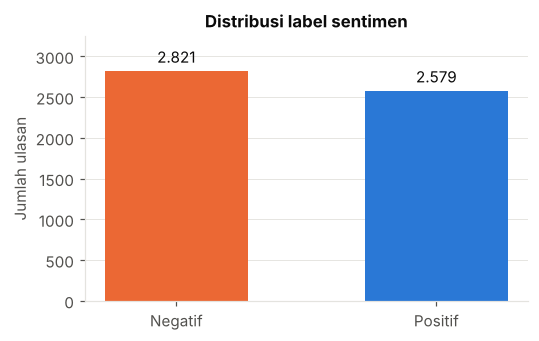

In [4]:
dist = df_raw["Sentiment"].value_counts()
display(pd.DataFrame({"jumlah": dist, "persen": (dist / len(df_raw) * 100).round(1)}))

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(["Negatif", "Positif"], [dist["Negative"], dist["Positive"]], color=[NEG, POS], width=0.55)
for b in bars:
    ax.annotate(f"{int(b.get_height()):,}".replace(",", "."), (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", color=INK)
ax.set_ylim(0, dist.max() * 1.15)
ax.set_title("Distribusi label sentimen")
ax.set_ylabel("Jumlah ulasan")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIG / "01_distribusi_label.png"); plt.show()

Kelas relatif seimbang (sekitar 52% negatif dan 48% positif), sehingga tidak perlu teknik penyeimbangan kelas. F1 macro tetap dipakai sebagai metrik utama agar kedua kelas dihitung setara.

### 2.2 Panjang ulasan

,count,mean,std,min,25%,50%,75%,max
Sentiment,,,,,,,,
Negative,2821.0,18.9,18.5,1.0,7.0,14.0,24.0,184.0
Positive,2579.0,13.0,11.0,1.0,6.0,10.0,17.0,151.0


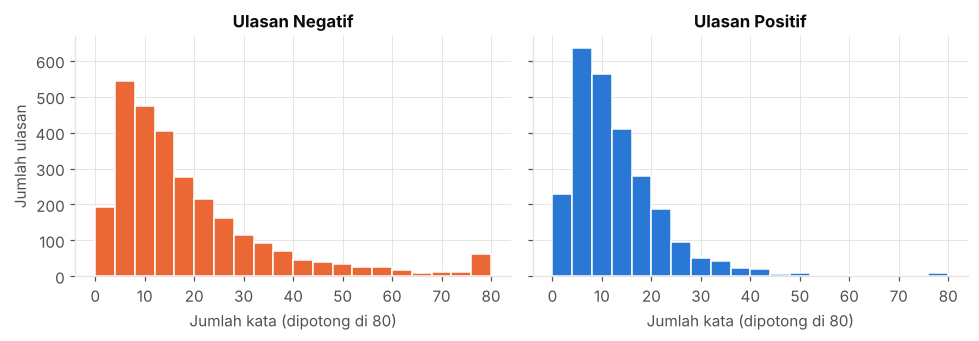

In [5]:
df_raw["jumlah_kata"] = df_raw["Customer Review"].str.split().str.len()
display(df_raw.groupby("Sentiment")["jumlah_kata"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
bins = np.arange(0, 81, 4)
for ax, (lab, warna, nama) in zip(axes, [("Negative", NEG, "Negatif"), ("Positive", POS, "Positif")]):
    ax.hist(df_raw.loc[df_raw.Sentiment == lab, "jumlah_kata"].clip(upper=80), bins=bins, color=warna, edgecolor="white", linewidth=1)
    ax.set_title(f"Ulasan {nama}")
    ax.set_xlabel("Jumlah kata (dipotong di 80)")
axes[0].set_ylabel("Jumlah ulasan")
plt.tight_layout(); plt.savefig(FIG / "02_panjang_ulasan.png"); plt.show()

Ulasan umumnya pendek. Ulasan negatif cenderung lebih panjang karena pembeli biasanya menjelaskan masalah yang dialami.

### 2.3 Pengecekan kebocoran label

Kolom *Customer Rating* dan *Emotion* perlu dicek, karena kalau keduanya hampir menentukan label, kolom tersebut tidak boleh dipakai sebagai fitur.

In [6]:
display(pd.crosstab(df_raw["Customer Rating"], df_raw["Sentiment"], margins=True))
display(pd.crosstab(df_raw["Emotion"], df_raw["Sentiment"]))

Sentiment,Negative,Positive,All
Customer Rating,,,
1,1832,0,1832
2,561,0,561
3,405,57,462
4,18,377,395
5,5,2145,2150
All,2821,2579,5400


Sentiment,Negative,Positive
Emotion,,
Anger,699,0
Fear,920,0
Happy,0,1770
Love,0,809
Sadness,1202,0


Rating 1–2 selalu negatif, rating 4–5 hampir selalu positif, dan setiap emosi hanya muncul pada satu sentimen. **Kedua kolom tidak dipakai sebagai fitur.** Satu-satunya fitur adalah teks ulasan.

### 2.4 Sebaran sentimen per kategori produk

In [7]:
kat = pd.crosstab(df_raw["Category"], df_raw["Sentiment"])
kat["persen_negatif"] = (kat["Negative"] / kat.sum(axis=1) * 100).round(1)
kat = kat.sort_values("persen_negatif")
display(kat.head(6))
print("Kategori tanpa ulasan negatif:", list(kat.index[kat["Negative"] == 0]))

Sentiment,Negative,Positive,persen_negatif
Category,,,
Property,0,40,0.0
Tour and Travel,0,80,0.0
Precious Metal,0,80,0.0
Beauty,100,100,50.0
Household,100,100,50.0
Books,100,100,50.0


Kategori tanpa ulasan negatif: ['Property', 'Tour and Travel', 'Precious Metal']


Tiga kategori hanya berisi ulasan positif. Kolom kategori tidak dipakai sebagai fitur, tetapi kondisi ini dicatat sebagai potensi bias kosakata pada bagian keterbatasan.

### 2.5 Emoji yang rusak dan teks duplikat

Emoji pada dataset rusak saat pengumpulan data dan tersimpan sebagai tanda tanya, umumnya "??" untuk satu emoji.

In [8]:
ada_emoji_rusak = df_raw["Customer Review"].str.contains(r"\?\?")
print("Ulasan dengan '??'           :", ada_emoji_rusak.sum(), f"({ada_emoji_rusak.mean():.1%})")
print(ada_emoji_rusak.groupby(df_raw["Sentiment"]).sum().to_dict())
print("Ulasan dengan karakter rusak :", df_raw["Customer Review"].str.contains("\ufffd").sum())
print("Teks ulasan duplikat         :", df_raw["Customer Review"].duplicated().sum())
dup = df_raw[df_raw["Customer Review"].duplicated(keep=False)]
print("Duplikat dengan label berbeda:", (dup.groupby("Customer Review")["Sentiment"].nunique() > 1).sum())
df_raw.loc[ada_emoji_rusak, "Customer Review"].head(5)

Ulasan dengan '??'           : 760 (14.1%)
{'Negative': 194, 'Positive': 566}
Ulasan dengan karakter rusak : 85
Teks ulasan duplikat         : 95
Duplikat dengan label berbeda: 0


3                                                          bagus sesuai harapan penjual nya juga ramah. trimakasih pelapak ??
16    Produknya baik dan kualitasny good banget. produk sampai ke konsumen dalam kondisi baik. sesuai sih sama harga juga ...
21    Kualitas barang bagus, harga relatif murah, kiriman super cepat, response penjual baik, recommended seller, bintang ...
25                              Barang cepat sampai. Kualitas bagus dan pengiriman aman tidak ada yang pecah. Manstapu ??????
30    Penjualnya Ramah Melayani Pembeli Dengan Sabar dan Memberikan Berbagai Saran Yang Pembeli Tidak Tahu ... Mantap Lah ...
Name: Customer Review, dtype: str

## 3. Pembersihan Data

- Mengambil kolom yang dipakai (teks ulasan dan label). Kolom kategori disimpan hanya untuk analisis kesalahan nanti.
- Menghapus teks ulasan duplikat. Tidak ada duplikat dengan label berbeda, jadi cukup menyimpan kemunculan pertama.
- Mengubah label menjadi angka (Negative = 0, Positive = 1).

In [9]:
df = (df_raw[["Customer Review", "Sentiment", "Category"]]
      .rename(columns={"Customer Review": "ulasan", "Sentiment": "sentimen", "Category": "kategori"})
      .drop_duplicates(subset="ulasan", keep="first")
      .reset_index(drop=True))
df["label"] = (df["sentimen"] == "Positive").astype(int)
print("Sebelum:", len(df_raw), "| Sesudah:", len(df), "| Dihapus:", len(df_raw) - len(df))
df["sentimen"].value_counts()

Sebelum: 5400 | Sesudah: 5305 | Dihapus: 95


sentimen
Negative    2752
Positive    2553
Name: count, dtype: int64

## 4. Kurasi Kamus Normalisasi

Sumber kamus adalah *Colloquial Indonesian Lexicon* (Salsabila dkk., 2018). Kamus ini disusun dari data Twitter, sehingga perlu disesuaikan untuk ulasan produk. Aturan kurasi:

1. **Bersihkan entri.** Huruf kecil, hapus spasi, buang entri yang bentuk tidak baku dan bakunya sama.
2. **Selesaikan entri ambigu.** Kata yang punya lebih dari satu bentuk baku dipertahankan hanya jika satu bentuk mencakup minimal 90% kemunculannya di kamus. Sisanya dibuang.
3. **Buang entri yang keliru** untuk konteks ulasan (kata baku yang tercatat sebagai tidak baku, kata bahasa Inggris, dan huruf tunggal yang ambigu).
4. **Koreksi pemetaan** yang salah konteks, misalnya "brg" ke "bareng" padahal di ulasan artinya "barang".
5. **Seragamkan negasi.** Semua bentuk negasi dipetakan ke "tidak", termasuk bentuk baku tidak resmi "enggak". Di kamus asli, "ga" dan "gak" dipetakan ke "enggak" sedangkan "tdk" ke "tidak", sehingga negasi tetap terpecah ke dua fitur.
6. **Resolusi berantai.** Bentuk baku yang ternyata masih tidak baku (misalnya "kalo") dinormalisasi sekali lagi.

In [10]:
lex = pd.read_csv(RES / "colloquial-indonesian-lexicon.csv")
print("Entri kamus asli:", len(lex))
lex["slang"] = lex["slang"].astype(str).str.strip().str.lower()
lex["formal"] = lex["formal"].astype(str).str.strip().str.lower()
lex = lex[(lex["slang"] != lex["formal"]) & (lex["slang"] != "") & (lex["formal"] != "")]

dibuang = []  # catatan entri yang dibuang beserta alasannya

# Aturan 2: entri ambigu
kamus = {}
for slang, grp in lex.groupby("slang"):
    hitung = grp["formal"].value_counts()
    if hitung.iloc[0] / hitung.sum() >= 0.9:
        kamus[slang] = hitung.index[0]
    else:
        dibuang.append((slang, " / ".join(hitung.index[:3]), "ambigu (tidak ada bentuk baku dominan)"))
kamus_awal = dict(kamus)  # disimpan untuk mencatat asal setiap entri
print("Entri unik setelah aturan 1-2:", len(kamus))

Entri kamus asli: 15006


Entri unik setelah aturan 1-2: 4267


In [11]:
# Aturan 3: entri yang keliru untuk konteks ulasan
BUANG = {
    "minta": "kata baku, bukan kata tidak baku",
    "in": "kata bahasa Inggris (misalnya 'check in')",
    "it": "kata bahasa Inggris",
    "so": "kata bahasa Inggris, bukan 'sok'",
    "to": "kata bahasa Inggris, bukan 'tapi'",
    "m": "huruf tunggal ambigu",
    "ma": "ambigu (sama / mama)",
    "cd": "ambigu (celana dalam / compact disc)",
}
for w, alasan in BUANG.items():
    if w in kamus:
        dibuang.append((w, kamus.pop(w), alasan))

# Aturan 4: koreksi pemetaan yang salah konteks
KOREKSI = {
    "brg": "barang", "dah": "sudah", "kw": "tiruan",
    "kaya": "seperti", "kayak": "seperti", "kyk": "seperti", "kek": "seperti", "ky": "seperti",
    "kalo": "kalau", "klo": "kalau", "kl": "kalau",
    "gw": "saya", "gue": "saya",
}
koreksi_log = [(w, kamus.get(w, "-"), b) for w, b in KOREKSI.items()]
kamus.update(KOREKSI)

# Aturan 5: seragamkan negasi
NEGASI = ["enggak", "engga", "nggak", "ngga", "gak", "ga", "gk", "g", "gx", "ngak", "ngk", "nga",
          "kagak", "kaga", "ndak", "nda", "tdk", "tak"]
for w in NEGASI:
    kamus[w] = "tidak"
for w, b in list(kamus.items()):
    if "enggak" in b.split():
        kamus[w] = " ".join("tidak" if t == "enggak" else t for t in b.split())
kamus.pop("tak", None)  # "tak" sudah baku, tidak perlu entri

# Aturan 6: resolusi berantai (satu kali)
for w, b in list(kamus.items()):
    kamus[w] = " ".join(kamus.get(t, t) for t in b.split())

pd.DataFrame(koreksi_log, columns=["slang", "sebelum", "sesudah"])

,slang,sebelum,sesudah
0,brg,bareng,barang
1,dah,deh,sudah
2,kw,kau,tiruan
3,kaya,kayak,seperti
4,kayak,-,seperti
5,kyk,kayak,seperti
6,kek,kayak,seperti
7,ky,kaya,seperti
8,kalo,-,kalau
9,klo,kalo,kalau


In [12]:
def asal_entri(w):
    if w in KOREKSI:
        return "koreksi manual"
    if w in NEGASI:
        return "penyeragaman negasi"
    if "enggak" in kamus_awal.get(w, "").split():
        return "lexicon (negasi diseragamkan)"
    return "lexicon"

df_kamus = pd.DataFrame({"slang": list(kamus), "formal": list(kamus.values())})
df_kamus["sumber"] = df_kamus["slang"].map(asal_entri)
df_kamus = df_kamus.sort_values("slang").reset_index(drop=True)
df_kamus.to_csv(RES / "kamus_normalisasi.csv", index=False)

df_buang = pd.DataFrame(dibuang, columns=["slang", "formal_asli", "alasan"])
df_buang.to_csv(RES / "kamus_dibuang.csv", index=False)

print("Entri kamus hasil kurasi :", len(df_kamus))
print("Entri yang dibuang       :", len(df_buang))
display(df_kamus["sumber"].value_counts())
display(df_buang[df_buang["alasan"] != "ambigu (tidak ada bentuk baku dominan)"])

Entri kamus hasil kurasi : 4264
Entri yang dibuang       : 71


sumber
lexicon                          4189
lexicon (negasi diseragamkan)      45
penyeragaman negasi                17
koreksi manual                     13
Name: count, dtype: int64

,slang,formal_asli,alasan
63,minta,meminta,"kata baku, bukan kata tidak baku"
64,in,ini,kata bahasa Inggris (misalnya 'check in')
65,it,itu,kata bahasa Inggris
66,so,sok,"kata bahasa Inggris, bukan 'sok'"
67,to,tapi,"kata bahasa Inggris, bukan 'tapi'"
68,m,sama,huruf tunggal ambigu
69,ma,sama,ambigu (sama / mama)
70,cd,celana dalam,ambigu (celana dalam / compact disc)


In [13]:
# Cek cepat: negasi sudah seragam
contoh = ["ga", "gak", "gk", "nggak", "tdk", "gabisa", "gpp", "gaada", "brg", "dah", "klo", "yg", "bgt", "d"]
pd.DataFrame({"slang": contoh, "formal": [kamus.get(w, "(tidak ada di kamus)") for w in contoh]})

,slang,formal
0,ga,tidak
1,gak,tidak
2,gk,tidak
3,nggak,tidak
4,tdk,tidak
5,gabisa,tidak bisa
6,gpp,tidak apa-apa
7,gaada,tidak ada
8,brg,barang
9,dah,sudah


## 5. Kata Tidak Baku pada Dataset

Proporsi ulasan yang memuat kata tidak baku dihitung setelah case folding dan cleaning, memakai kamus hasil kurasi.

In [14]:
df["token_bersih"] = df["ulasan"].map(lambda t: tokenisasi(cleaning(case_folding(t))))
df["ada_tidak_baku"] = df["token_bersih"].map(lambda ts: any(t in kamus for t in ts))
semua_token = [t for ts in df["token_bersih"] for t in ts]
token_tb = [t for t in semua_token if t in kamus]

print(f"Ulasan dengan kata tidak baku : {df['ada_tidak_baku'].mean():.1%}")
print(df.groupby("sentimen")["ada_tidak_baku"].mean().map("{:.1%}".format).to_dict())
print(f"Porsi token tidak baku        : {len(token_tb) / len(semua_token):.1%}")

Ulasan dengan kata tidak baku : 59.6%
{'Negative': '71.5%', 'Positive': '46.8%'}
Porsi token tidak baku        : 11.9%


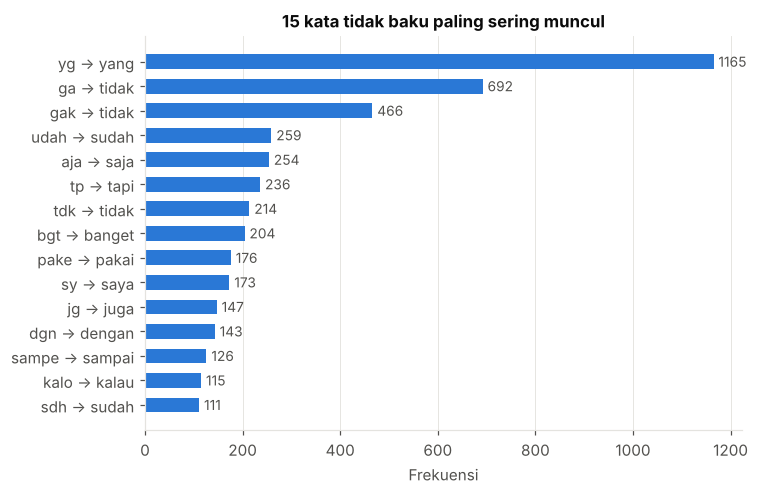

In [15]:
top = collections.Counter(token_tb).most_common(15)
top_df = pd.DataFrame(top, columns=["slang", "frekuensi"])
top_df["formal"] = top_df["slang"].map(kamus)

fig, ax = plt.subplots(figsize=(7, 4.6))
y = np.arange(len(top_df))[::-1]
ax.barh(y, top_df["frekuensi"], color=BAR, height=0.6)
ax.set_yticks(y, [f"{s} → {f}" for s, f in zip(top_df["slang"], top_df["formal"])])
for yi, v in zip(y, top_df["frekuensi"]):
    ax.text(v + 10, yi, str(v), va="center", color=INK2, fontsize=9)
ax.set_title("15 kata tidak baku paling sering muncul")
ax.set_xlabel("Frekuensi")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "03_kata_tidak_baku_teratas.png"); plt.show()

## 6. Preprocessing Dua Skenario

| Langkah | Skenario A | Skenario B |
|---|---|---|
| Case folding | ✓ | ✓ |
| Cleaning (URL, "??" emoji rusak, karakter rusak, tanda baca, angka, huruf berulang) | ✓ | ✓ |
| Tokenisasi | ✓ | ✓ |
| **Normalisasi kata tidak baku** | – | ✓ |
| Stopword removal (kata negasi dan kata penilai dipertahankan) | ✓ | ✓ |

### 6.1 Daftar stopword

Daftar dasar adalah stopword bahasa Indonesia dari NLTK (758 kata). Kata yang membawa makna sentimen dikeluarkan dari daftar agar tidak terhapus.

In [16]:
sw_nltk = (RES / "stopwords_nltk_indonesian.txt").read_text(encoding="utf-8").split()
DIPERTAHANKAN = ["tidak", "bukan", "belum", "jangan", "tanpa", "tak", "enggak", "kurang", "cukup", "agak",
                 "baik", "benar", "tepat", "lama", "lebih", "paling", "sangat", "sekali", "terlalu",
                 "tapi", "tetapi", "namun", "baru"]
stopwords = sorted(set(sw_nltk) - set(DIPERTAHANKAN))
(RES / "stopwords_id.txt").write_text("\n".join(stopwords), encoding="utf-8")
stopwords = set(stopwords)
print("Stopword NLTK:", len(set(sw_nltk)), "| dipakai:", len(stopwords), "| dipertahankan:", len(DIPERTAHANKAN))

Stopword NLTK: 757 | dipakai: 734 | dipertahankan: 23


### 6.2 Menjalankan preprocessing

In [17]:
df["teks_A"] = df["ulasan"].map(lambda t: preprocess(t, stopwords))
df["teks_B"] = df["ulasan"].map(lambda t: preprocess(t, stopwords, kamus))

kosong = {s: int((df[f"teks_{s}"].str.len() == 0).sum()) for s in "AB"}
print("Ulasan yang kosong setelah preprocessing:", kosong)

cek = df[df["ada_tidak_baku"]].sample(6, random_state=SEED)[["ulasan", "teks_A", "teks_B", "sentimen"]]
cek

Ulasan yang kosong setelah preprocessing: {'A': 0, 'B': 0}


,ulasan,teks_A,teks_B,sentimen
4649,respon seller ok.Barang sesuai deskripsi dan mudah pemasangan sejauh ini puas. Saran membangun untuk stik ps bawaan ...,respon seller ok barang sesuai deskripsi mudah pemasangan puas saran membangun stik ps bawaan ditingkatkan pilihan u...,respon seller ok barang sesuai deskripsi mudah pemasangan puas saran membangun stik pas bawaan ditingkatkan pilihan ...,Positive
556,Pesan yg varian 20pcs tp cuma dikirim 10pcs,pesan yg varian pcs tp dikirim pcs,pesan varian pcs tapi dikirim pcs,Negative
293,bocor payahlah ga di periksa dulu,bocor payahlah ga periksa,bocor payahlah tidak periksa,Negative
568,kue nya pas Dateng dicoba asem..kue Uda terlalu lama..di komplain ke penjual bilang nya bisa dikonsumsi dan dimakan....,kue nya pas dateng dicoba asem kue uda terlalu lama komplain penjual bilang nya dikonsumsi dimakan tidak tanggung,kue nya pas dicoba asem kue terlalu lama komplain penjual bilang nya dikonsumsi dimakan tidak tanggung,Negative
2692,psen yg mix dikirimnya warna orange,psen yg mix dikirimnya warna orange,psen mix dikirimnya warna orange,Negative
1231,Kecewa wanginya biasa aja. Wanginya ga tahan 1 jam boro2 bisa 12 jam sprti iklannya. Masih bagus bibit parfum pinggi...,kecewa wanginya aja wanginya ga tahan jam boro jam sprti iklannya bagus bibit parfum pinggir jalan deh,kecewa wanginya wanginya tidak tahan jam boro jam iklannya bagus bibit parfum pinggir jalan deh,Negative


Ulasan yang menjadi kosong (hanya berisi stopword atau emoji) tidak dihapus di tahap ini, agar jumlah data kedua skenario tetap sama. Penanganannya diputuskan di tahap pemodelan.

### 6.3 Dampak normalisasi terhadap kosakata

In [18]:
def ringkas(kol):
    tok = [t for s in df[kol] for t in s.split()]
    return {"jumlah token": len(tok), "kosakata unik": len(set(tok)), "rata-rata token per ulasan": round(len(tok) / len(df), 2)}

banding = pd.DataFrame({"Skenario A": ringkas("teks_A"), "Skenario B": ringkas("teks_B")})
banding["selisih"] = banding["Skenario B"] - banding["Skenario A"]
banding

,Skenario A,Skenario B,selisih
jumlah token,64694.00,59582.00,-5112.00
kosakata unik,7760.00,7157.00,-603.00
rata-rata token per ulasan,12.19,11.23,-0.96


In [19]:
NEG_VARIAN = ["tidak", "tdk", "ga", "gak", "gk", "nggak", "ngga", "g", "enggak", "engga", "gx"]
def hitung_negasi(kol):
    c = collections.Counter(t for s in df[kol] for t in s.split())
    return {w: c[w] for w in NEG_VARIAN}
pd.DataFrame({"Skenario A": hitung_negasi("teks_A"), "Skenario B": hitung_negasi("teks_B")})

,Skenario A,Skenario B
tidak,1179,3014
tdk,214,0
ga,692,0
gak,466,0
gk,107,0
nggak,61,0
ngga,63,0
g,49,0
enggak,9,0
engga,10,0


Di Skenario A, makna "tidak" tersebar ke banyak bentuk penulisan. Di Skenario B, semuanya menyatu menjadi satu fitur "tidak". Ini contoh nyata mekanisme yang ingin diuji pengaruhnya terhadap Naive Bayes dan K-NN.

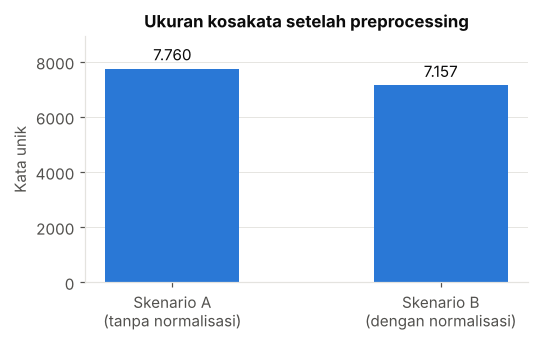

In [20]:
fig, ax = plt.subplots(figsize=(5, 3.2))
v = [banding.loc["kosakata unik", "Skenario A"], banding.loc["kosakata unik", "Skenario B"]]
bars = ax.bar(["Skenario A\n(tanpa normalisasi)", "Skenario B\n(dengan normalisasi)"], v, color=BAR, width=0.5)
for b in bars:
    ax.annotate(f"{int(b.get_height()):,}".replace(",", "."), (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", color=INK)
ax.set_ylim(0, max(v) * 1.15)
ax.set_title("Ukuran kosakata setelah preprocessing")
ax.set_ylabel("Kata unik")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIG / "04_ukuran_kosakata.png"); plt.show()

## 7. Menyimpan Data Bersih

In [21]:
out = df[["ulasan", "teks_A", "teks_B", "label", "sentimen", "kategori", "ada_tidak_baku"]]
out.to_csv(DATA_OUT, index=False)
print("Tersimpan:", DATA_OUT.relative_to(ROOT), out.shape)
out.head(3)

Tersimpan: data/processed/prdect_clean.csv (5305, 7)


,ulasan,teks_A,teks_B,label,sentimen,kategori,ada_tidak_baku
0,Alhamdulillah berfungsi dengan baik. Packaging aman. Respon cepat dan ramah. Seller dan kurir amanah,alhamdulillah berfungsi baik packaging aman respon cepat ramah seller kurir amanah,alhamdulillah berfungsi baik packaging aman respon cepat ramah seller kurir amanah,1,Positive,Computers and Laptops,False
1,"barang bagus dan respon cepat, harga bersaing dengan yg lain.",barang bagus respon cepat harga bersaing yg,barang bagus respon cepat harga bersaing,1,Positive,Computers and Laptops,True
2,"barang bagus, berfungsi dengan baik, seler ramah, pengiriman cepat",barang bagus berfungsi baik seler ramah pengiriman cepat,barang bagus berfungsi baik seler ramah pengiriman cepat,1,Positive,Computers and Laptops,False


## 8. Ringkasan

- Data bersih berisi 5.305 ulasan setelah 95 duplikat dihapus, dengan label relatif seimbang.
- *Customer Rating* dan *Emotion* tidak dipakai sebagai fitur karena menyebabkan kebocoran label.
- Kamus normalisasi dikurasi dari *Colloquial Indonesian Lexicon* dan disimpan di `resources/kamus_normalisasi.csv`. Entri yang dibuang beserta alasannya ada di `resources/kamus_dibuang.csv`.
- Kolom `teks_A` dan `teks_B` di `data/processed/prdect_clean.csv` siap dipakai untuk tahap berikutnya, yaitu TF-IDF, Multinomial Naive Bayes, dan K-NN pada keempat skenario.